# Разработка A/B-тестирования и анализ результатов

В приложении существует две модели монетизации: первая — ежемесячная платная подписка, которая позволяет пользователям смотреть ленту без рекламы, вторая — демонстрация рекламы для пользователей, которые ещё не оформили подписку.

Команда разработчиков рекомендательных систем создала новый алгоритм рекомендаций, который, по их мнению, будет показывать более интересный контент для каждого пользователя. Нас просят помочь рассчитать параметры A/B-теста, который позволит проверить эту гипотезу, и проанализировать его результаты.

## Описание данных

Мы будем работать с тремя таблицами:

- `sessions_project_history.csv` — таблица с историческими данными по сессиям пользователей на период с 2025-08-15 по 2025-09-23. Путь к файлу: `/datasets/sessions_project_history.csv`.

- `sessions_project_test_part.csv` — таблица с данными за первый день проведения A/B-теста, то есть за 2025-10-14. Путь к файлу: `/datasets/sessions_project_test_part.csv`.

- `sessions_project_test.csv` — таблица с данными за весь период проведения A/B-теста, то есть с 2025-10-14 по 2025-11-02. Путь к файлу: `/datasets/sessions_project_test.csv`.

У этих таблиц почти совпадает структура и содержание колонок, различаются лишь периоды наблюдения.

Поля таблиц `sessions_project_history.csv`, `sessions_project_test.csv`, `sessions_project_test_part.csv`:

- `user_id` — идентификатор пользователя;

- `session_id` — идентификатор сессии в приложении;

- `session_date` — дата сессии;

- `session_start_ts` — дата и время начала сессии;

- `install_date` — дата установки приложения;

- `session_number` — порядковый номер сессии для конкретного пользователя;

- `registration_flag` — является ли пользователь зарегистрированным;

- `page_counter` — количество просмотренных страниц во время сессии;

- `region` — регион пользователя;

- `device` — тип устройства пользователя;

- `test_group` — тестовая группа (в таблице с историческими данными этого столбца нет).


## Что нужно сделать
Наши задачи: рассчитать параметры теста, оценить корректность его проведения и проанализировать результаты эксперимента.

### 1. Работа с историческими данными (EDA)

#### 1.1. Загрузка исторических данных
На первом этапе поработаем с историческими данными приложения:

- Импортируем библиотеку pandas.

- Считаем и сохраним в датафрейм `sessions_history` CSV-файл с историческими данными о сессиях пользователей `sessions_project_history.csv`.

Выведем на экран первые пять строк полученного датафрейма.

In [1]:
import pandas as pd

sessions_history = pd.read_csv('/datasets/sessions_project_history.csv')

print(sessions_history.head())

            user_id        session_id session_date     session_start_ts  \
0  E302123B7000BFE4  F9AF61A0C2023832   2025-08-15  2025-08-15 17:47:35   
1  2530F72E221829FB  85003A206CBDAC6F   2025-08-15  2025-08-15 16:42:14   
2  876E020A4FC512F5  3677423E49D72DEE   2025-08-15  2025-08-15 12:30:00   
3  2640B349E1D81584  956B45F5915CA225   2025-08-15  2025-08-15 15:31:31   
4  94E1CBFAEF1F5EE9  83BF0DA35F9F1F40   2025-08-15  2025-08-15 21:33:53   

  install_date  session_number  registration_flag  page_counter region  \
0   2025-08-15               1                  0             3    CIS   
1   2025-08-15               1                  0             4   MENA   
2   2025-08-15               1                  0             4     EU   
3   2025-08-15               1                  0             4    CIS   
4   2025-08-15               1                  0             3    CIS   

    device  
0   iPhone  
1  Android  
2       PC  
3  Android  
4  Android  


#### 1.2. Знакомство с данными
- Для каждого уникального пользователя `user_id` рассчитаем количество уникальных сессий `session_id`.

- Выведем на экран все данные из таблицы `sessions_history` для одного пользователя с наибольшим количеством сессий. Если таких пользователей несколько, выберем любого из них.

- Изучим таблицу для одного пользователя, чтобы лучше понять логику формирования каждого столбца данных.

In [2]:
sessions_per_user = sessions_history.groupby('user_id')['session_id'].nunique().reset_index(name='sessions_count')

top_user = sessions_per_user.sort_values('sessions_count', ascending=False).iloc[0]
top_user_id = top_user['user_id']
max_sessions = top_user['sessions_count']

print(f"Пользователь с наибольшим количеством сессий: {top_user_id}")
print(f"Количество его уникальных сессий: {max_sessions}\n")

user_data = sessions_history[sessions_history['user_id'] == top_user_id]

print(f"Все данные из таблицы для пользователя {top_user_id}:")
print(user_data)

Пользователь с наибольшим количеством сессий: 10E0DEFC1ABDBBE0
Количество его уникальных сессий: 10

Все данные из таблицы для пользователя 10E0DEFC1ABDBBE0:
                 user_id        session_id session_date     session_start_ts  \
115558  10E0DEFC1ABDBBE0  B8F0423BBFFCF5DC   2025-08-14  2025-08-14 13:57:39   
191751  10E0DEFC1ABDBBE0  87CA2FA549473837   2025-08-15  2025-08-15 16:42:10   
239370  10E0DEFC1ABDBBE0  4ADD8011DCDCE318   2025-08-16  2025-08-16 19:53:21   
274629  10E0DEFC1ABDBBE0  DF0FD0E09BF1F3D7   2025-08-17  2025-08-17 15:03:43   
302501  10E0DEFC1ABDBBE0  3C221774B4DE6885   2025-08-18  2025-08-18 17:29:14   
325557  10E0DEFC1ABDBBE0  031BD7A67048105B   2025-08-19  2025-08-19 13:23:55   
345336  10E0DEFC1ABDBBE0  FF4315CF4AD4B100   2025-08-20  2025-08-20 19:31:54   
377532  10E0DEFC1ABDBBE0  4045FEA0747203B4   2025-08-22  2025-08-22 17:54:13   
403538  10E0DEFC1ABDBBE0  344B086C421C7F37   2025-08-24  2025-08-24 14:46:13   
414743  10E0DEFC1ABDBBE0  054F20BA371E4C9D

#### 1.3. Анализ числа регистраций
Одна из важнейших метрик продукта — число зарегистрированных пользователей. Используя исторические данные, визуализируем, как менялось число регистраций в приложении за время его существования. Пользователь считается зарегистрированным только в день совершения регистрации. Таким образом, нам необходимо проанализировать количество зарегистрированных активных пользователей за каждый день без накопления.

- Агрегируем исторические данные и рассчитаем число уникальных пользователей и число зарегистрированных пользователей для каждого дня наблюдения. Для простоты считаем, что у пользователя в течение дня бывает одна сессия максимум и статус регистрации в течение одного дня не может измениться.

- Построим линейные графики общего числа пользователей и общего числа зарегистрированных пользователей по дням. Отобразим их на одном графике.

- Построим отдельный линейный график доли зарегистрированных пользователей от всех пользователей по дням.

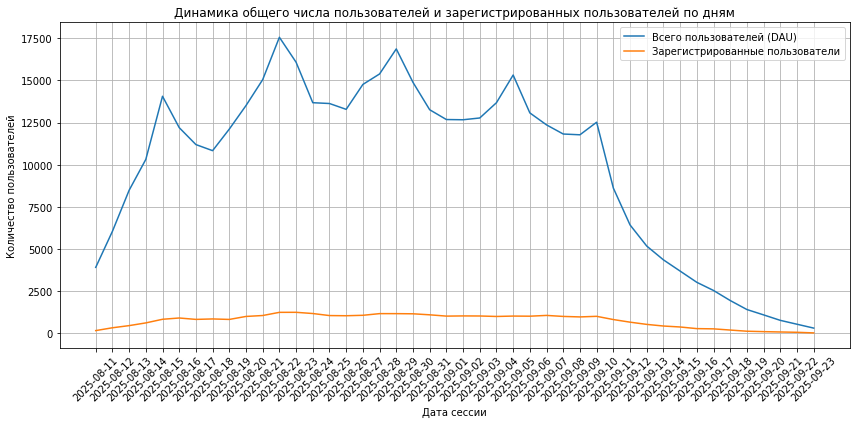

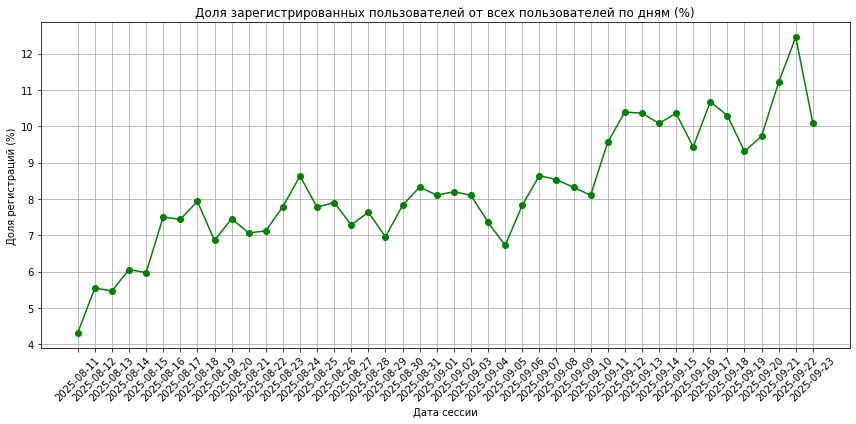

In [3]:
import matplotlib.pyplot as plt

daily_stats = sessions_history.groupby('session_date').agg(
    unique_users=('user_id', 'nunique'),
    registered_users=('registration_flag', 'sum')
).reset_index()

plt.figure(figsize=(12, 6))
plt.plot(daily_stats['session_date'], daily_stats['unique_users'], label='Всего пользователей (DAU)')
plt.plot(daily_stats['session_date'], daily_stats['registered_users'], label='Зарегистрированные пользователи')

plt.title('Динамика общего числа пользователей и зарегистрированных пользователей по дням')
plt.xlabel('Дата сессии')
plt.ylabel('Количество пользователей')
plt.grid(True)
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

daily_stats['registration_rate'] = (daily_stats['registered_users'] / daily_stats['unique_users']) * 100

plt.figure(figsize=(12, 6))
plt.plot(daily_stats['session_date'], daily_stats['registration_rate'], color='green', marker='o')

plt.title('Доля зарегистрированных пользователей от всех пользователей по дням (%)')
plt.xlabel('Дата сессии')
plt.ylabel('Доля регистраций (%)')
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### 1.4. Анализ числа просмотренных страниц
Другая важная метрика продукта — число просмотренных страниц в приложении. Чем больше страниц просмотрено, тем сильнее пользователь увлечён контентом, а значит, выше шансы, что он зарегистрируется и оплатит подписку.

В рамках задания проанализируем число просмотренных страниц во время первых сессий пользователей. Найдем количество первых сессий для каждого значения количества просмотренных страниц. Например: одну страницу просмотрели в 8978 первых сессиях, две страницы — в 32 494 первых сессиях и так далее.

- Построим столбчатую диаграмму, где по оси X будет число просмотренных страниц, по оси Y — количество сессий.

Статистика по количеству просмотренных страниц в первых сессиях:
1     8978
2    32494
3    50939
4    32739
5     8075
6      777
7       37
Name: page_counter, dtype: int64


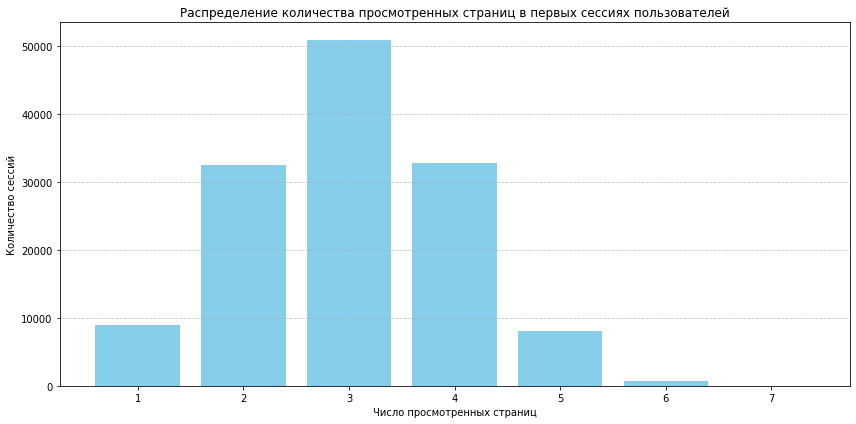

In [4]:
first_sessions = sessions_history[sessions_history['session_number'] == 1]

page_counts = first_sessions['page_counter'].value_counts().sort_index()

print("Статистика по количеству просмотренных страниц в первых сессиях:")
print(page_counts)

plt.figure(figsize=(12, 6))
plt.bar(page_counts.index, page_counts.values, color='skyblue')

plt.title('Распределение количества просмотренных страниц в первых сессиях пользователей')
plt.xlabel('Число просмотренных страниц')
plt.ylabel('Количество сессий')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(page_counts.index) 
plt.tight_layout()
plt.show()

#### 1.5. Доля пользователей, просмотревших более четырёх страниц
Продуктовая команда продукта считает, что первые сессии, в рамках которых пользователь просмотрел 4 и более страниц, говорят об удовлетворённости контентом и алгоритмами рекомендаций. Этот показатель является важной прокси-метрикой для продукта.

- В датафрейме `sessions_history` создадим дополнительный столбец `good_session`. В него войдёт значение `1`, если за одну сессию было просмотрено 4 и более страниц, и значение `0`, если было просмотрено меньше.

- Построим график со средним значением доли успешных первых сессий от всех первых сессий пользователей. Данные нужно визуализировать по дням за весь период наблюдения.

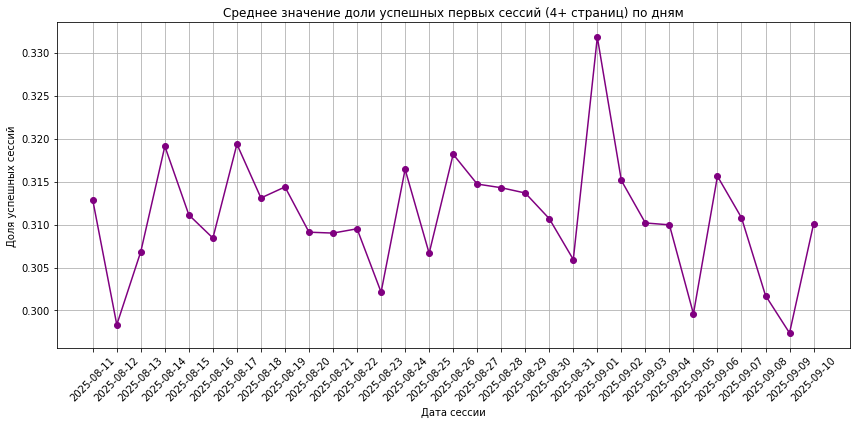

In [5]:
sessions_history['good_session'] = 0

sessions_history.loc[sessions_history['page_counter'] >= 4, 'good_session'] = 1

first_sessions = sessions_history[sessions_history['session_number'] == 1]

daily_good_rate = first_sessions.groupby('session_date')['good_session'].mean().reset_index()

plt.figure(figsize=(12, 6))
plt.plot(daily_good_rate['session_date'], daily_good_rate['good_session'], marker='o', color='purple')

plt.title('Среднее значение доли успешных первых сессий (4+ страниц) по дням')
plt.xlabel('Дата сессии')
plt.ylabel('Доля успешных сессий')
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 2. Подготовка к тесту
При планировании теста необходимо проделать несколько важных шагов:

- Определиться с целевой метрикой.

- Рассчитать необходимый размер выборки.

- Исходя из текущих значений трафика рассчитать необходимую длительность проведения теста.

#### 2.1. Расчёт размера выборки

In [6]:
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

alpha = 0.05      
beta = 0.2        
power = 1 - beta  
p = 0.3           
mde = 0.03        

absolute_mde = p * mde 

effect_size = proportion_effectsize(p, p + absolute_mde)

power_analysis = NormalIndPower()

sample_size = power_analysis.solve_power(
    effect_size = effect_size,
    power = power,
    alpha = alpha,
    ratio = 1
)

print(f"Необходимый размер выборки для каждой группы: {int(sample_size)}")

Необходимый размер выборки для каждой группы: 41040


#### 2.2. Расчёт длительности A/B-теста

Используем данные о количестве пользователей в каждой выборке и среднем количестве пользователей приложения. Рассчитаем длительность теста, разделив одно на другое.

- Рассчитаем среднее количество уникальных пользователей приложения в день.

- Определим длительность теста исходя из рассчитанного значения размера выборок и среднего дневного трафика приложения. Количество дней округлим в большую сторону.

In [7]:
from math import ceil

avg_daily_users = daily_stats['unique_users'].mean()

test_duration = ceil((sample_size * 2) / avg_daily_users)

print(f"Рассчитанная длительность A/B-теста при текущем уровне трафика в {avg_daily_users:.0f} пользователей в день составит {test_duration} дней")

Рассчитанная длительность A/B-теста при текущем уровне трафика в 9907 пользователей в день составит 9 дней


### 3. Мониторинг А/В-теста

#### 3.1. Проверка распределения пользователей

A/B-тест успешно запущен, и уже доступны данные за первые три дня. На этом этапе нужно убедиться, что всё идёт хорошо: пользователи разделены правильным образом, а интересующие нас метрики корректно считаются.

- Считаем и сохраним в датафрейм `sessions_test_part` CSV-файл с историческими данными о сессиях пользователей `sessions_project_test_part.csv`.

- Рассчитаем количество уникальных пользователей в каждой из экспериментальных групп для одного дня наблюдения.

- Рассчитаем и выведем на экран процентную разницу в количестве пользователей в группах A и B. Построим удобную визуализацию, на которой будет видно возможное различие двух групп.

Для расчёта процентной разницы воспользуемся формулой:
$$P = 100 \cdot  \frac{|A − B|}{A}$$

Количество уникальных пользователей в группе A: 1477
Количество уникальных пользователей в группе B: 1466
Процентная разница в количестве пользователей: 0.74%


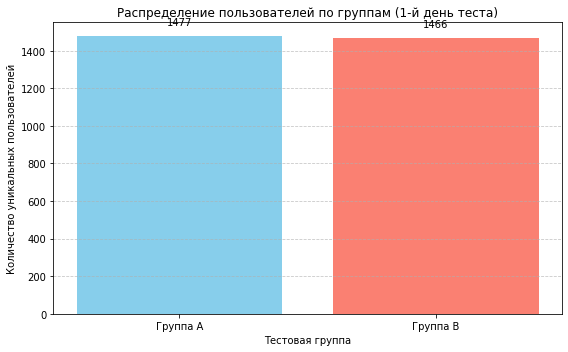

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

sessions_test_part = pd.read_csv('/datasets/sessions_project_test_part.csv')

users_A = sessions_test_part[sessions_test_part['test_group'] == 'A']['user_id'].nunique()
users_B = sessions_test_part[sessions_test_part['test_group'] == 'B']['user_id'].nunique()

print(f"Количество уникальных пользователей в группе A: {users_A}")
print(f"Количество уникальных пользователей в группе B: {users_B}")

percentage_diff = 100 * (abs(users_A - users_B) / users_A)
print(f"Процентная разница в количестве пользователей: {percentage_diff:.2f}%")

plt.figure(figsize=(8, 5))
plt.bar(['Группа A', 'Группа B'], [users_A, users_B], color=['skyblue', 'salmon'])
plt.title('Распределение пользователей по группам (1-й день теста)')
plt.xlabel('Тестовая группа')
plt.ylabel('Количество уникальных пользователей')
plt.grid(axis='y', linestyle='--', alpha=0.7)

for i, v in enumerate([users_A, users_B]):
    plt.text(i, v + 50, str(v), ha='center', va='bottom')

plt.tight_layout()
plt.show()

#### 3.2. Проверка пересечений пользователей
Помимо проверки равенства количества пользователей в группах, полезно убедиться в том, что группы независимы. Для этого нужно убедиться, что никто из пользователей случайно не попал в обе группы одновременно.

- Рассчитаем количество пользователей, которые встречаются одновременно в группах A и B, или убедимся, что таких нет.

In [9]:
users_set_A = set(sessions_test_part[sessions_test_part['test_group'] == 'A']['user_id'])
users_set_B = set(sessions_test_part[sessions_test_part['test_group'] == 'B']['user_id'])

intersection_users = users_set_A.intersection(users_set_B)

print(f"Количество пользователей, попавших в обе группы одновременно: {len(intersection_users)}")

if len(intersection_users) == 0:
    print("Группы полностью независимы. Пользователи не пересекаются.")
else:
    print("ВНИМАНИЕ! Обнаружены пересечения. Вот их ID:", intersection_users)

Количество пользователей, попавших в обе группы одновременно: 0
Группы полностью независимы. Пользователи не пересекаются.


#### 3.3. Равномерность разделения пользователей по устройствам
Полезно также убедиться в том, что пользователи равномерно распределены по всем доступным категориальным переменным — типам устройств и регионам.

Построим две диаграммы:

- доля каждого типа устройства для пользователей из группы A,

- доля каждого типа устройства для пользователей из группы B.

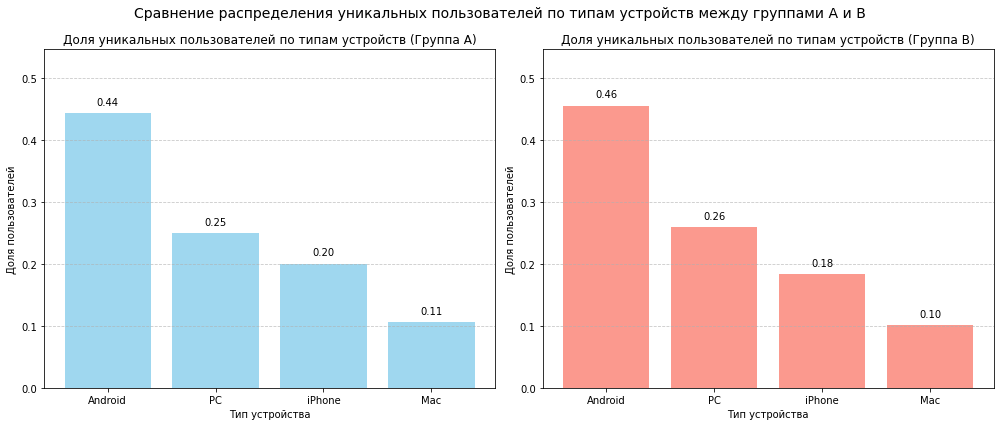

Доли устройств в группе A (по уникальным пользователям):
device
Android    0.444144
PC         0.249831
iPhone     0.200406
Mac        0.105619
Name: user_id, dtype: float64

Доли устройств в группе B (по уникальным пользователям):
device
Android    0.455662
PC         0.259891
iPhone     0.183492
Mac        0.100955
Name: user_id, dtype: float64


In [10]:
import matplotlib.pyplot as plt

group_a = sessions_test_part[sessions_test_part['test_group'] == 'A']
group_b = sessions_test_part[sessions_test_part['test_group'] == 'B']

device_dist_a = group_a.groupby('device')['user_id'].nunique() / group_a['user_id'].nunique()
device_dist_b = group_b.groupby('device')['user_id'].nunique() / group_b['user_id'].nunique()

device_dist_a = device_dist_a.sort_values(ascending=False)
device_dist_b = device_dist_b.sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].bar(device_dist_a.index, device_dist_a.values, color='skyblue', alpha=0.8)
axes[0].set_title('Доля уникальных пользователей по типам устройств (Группа A)')
axes[0].set_xlabel('Тип устройства')
axes[0].set_ylabel('Доля пользователей')
axes[0].set_ylim(0, max(device_dist_a.max(), device_dist_b.max()) * 1.2) 
axes[0].grid(axis='y', linestyle='--', alpha=0.7)
for i, v in enumerate(device_dist_a.values):
    axes[0].text(i, v + 0.01, f"{v:.2f}", ha='center', va='bottom')

axes[1].bar(device_dist_b.index, device_dist_b.values, color='salmon', alpha=0.8)
axes[1].set_title('Доля уникальных пользователей по типам устройств (Группа B)')
axes[1].set_xlabel('Тип устройства')
axes[1].set_ylabel('Доля пользователей')
axes[1].set_ylim(0, max(device_dist_a.max(), device_dist_b.max()) * 1.2)
axes[1].grid(axis='y', linestyle='--', alpha=0.7)
for i, v in enumerate(device_dist_b.values):
    axes[1].text(i, v + 0.01, f"{v:.2f}", ha='center', va='bottom')

fig.suptitle('Сравнение распределения уникальных пользователей по типам устройств между группами A и B', fontsize=14)

plt.tight_layout()
plt.show()

print("Доли устройств в группе A (по уникальным пользователям):")
print(device_dist_a)
print("\nДоли устройств в группе B (по уникальным пользователям):")
print(device_dist_b)

#### 3.4. Равномерность распределения пользователей по регионам
Теперь убедимся, что пользователи равномерно распределены по регионам.

Построим две диаграммы:

- доля каждого региона для пользователей из группы A,

- доля каждого региона для пользователей из группы B.

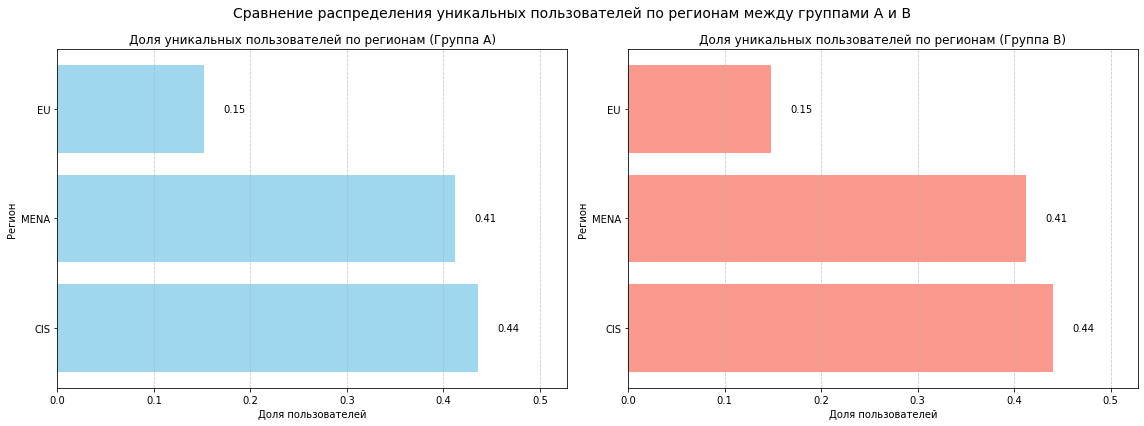

Доли регионов в группе A (по уникальным пользователям):
region
CIS     0.436019
MENA    0.412322
EU      0.151659
Name: user_id, dtype: float64

Доли регионов в группе B (по уникальным пользователям):
region
CIS     0.439973
MENA    0.412005
EU      0.148022
Name: user_id, dtype: float64


In [11]:
import matplotlib.pyplot as plt

group_a = sessions_test_part[sessions_test_part['test_group'] == 'A']
group_b = sessions_test_part[sessions_test_part['test_group'] == 'B']

region_dist_a = group_a.groupby('region')['user_id'].nunique() / group_a['user_id'].nunique()
region_dist_b = group_b.groupby('region')['user_id'].nunique() / group_b['user_id'].nunique()

region_dist_a = region_dist_a.sort_values(ascending=False)
region_dist_b = region_dist_b.sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].barh(region_dist_a.index, region_dist_a.values, color='skyblue', alpha=0.8)
axes[0].set_title('Доля уникальных пользователей по регионам (Группа A)')
axes[0].set_xlabel('Доля пользователей')
axes[0].set_ylabel('Регион')
axes[0].set_xlim(0, max(region_dist_a.max(), region_dist_b.max()) * 1.2)
axes[0].grid(axis='x', linestyle='--', alpha=0.7)
for i, v in enumerate(region_dist_a.values):
    axes[0].text(v + 0.02, i, f"{v:.2f}", va='center')

axes[1].barh(region_dist_b.index, region_dist_b.values, color='salmon', alpha=0.8)
axes[1].set_title('Доля уникальных пользователей по регионам (Группа B)')
axes[1].set_xlabel('Доля пользователей')
axes[1].set_ylabel('Регион')
axes[1].set_xlim(0, max(region_dist_a.max(), region_dist_b.max()) * 1.2)
axes[1].grid(axis='x', linestyle='--', alpha=0.7)
for i, v in enumerate(region_dist_b.values):
    axes[1].text(v + 0.02, i, f"{v:.2f}", va='center')

fig.suptitle('Сравнение распределения уникальных пользователей по регионам между группами A и B', fontsize=14)

plt.tight_layout()
plt.show()

print("Доли регионов в группе A (по уникальным пользователям):")
print(region_dist_a)
print("\nДоли регионов в группе B (по уникальным пользователям):")
print(region_dist_b)

## Выводы по проверке корректности проведения A/B-теста

На основе проведенного анализа данных первого дня теста можно сделать следующие выводы:

1. **Различие в количестве пользователей в двух группах:**
   Было обнаружено незначительное различие в размерах выборок. В группу A попало 1477 уникальных пользователей, а в группу B — 1466. Процентная разница составила всего **0.74%**, что является допустимой случайной вариацией при сплите. Тест сбалансирован по объему данных.

2. **Независимость выборок и отсутствие пересечений:**
   Выборки являются полностью независимыми. Количество пользователей, попавших одновременно в обе группы, составило **0**. Это подтверждает корректность распределения пользователей по группам и исключает возможность искажения результатов за счет "перетекания" пользователей между группами.

3. **Равномерность распределения по категориальным переменным:**
   *   **По типам устройств:** Распределение практически идентично. Доли Android, PC, iPhone и Mac в группах A и B отличаются друг от друга не более чем на 1-2%, что находится в пределах нормы.
   *   **По регионам:** Распределение также является равномерным. Доли пользователей из CIS, MENA и EU в группах A и B имеют небольшие колебания, что также является допустимой случайной ошибкой выборки.

**Общее заключение:**
A/B-тест проводится **корректно**. Никаких критических нарушений обнаружено не было. Группы сопоставимы по размеру, независимы и однородны по основным категориальным переменным, что позволяет переходить к анализу целевых метрик.

### 4. Проверка результатов A/B-теста

A/B-тест завершён, и у нас есть результаты за все дни проведения эксперимента. Необходимо убедиться в корректности теста и верно интерпретировать результаты.

#### 4.1. Получение результатов теста и подсчёт основной метрики

- Считаем и сохраним в датафрейм `sessions_test` CSV-файл с историческими данными о сессиях пользователей `sessions_project_test.csv`.

- В датафрейме `sessions_test` создадим дополнительный столбец `good_session`. В него войдёт значение `1`, если за одну сессию было просмотрено 4 и более страниц, и значение `0`, если просмотрено меньше.

In [12]:
import pandas as pd

sessions_test = pd.read_csv('/datasets/sessions_project_test.csv')

sessions_test['good_session'] = 0

sessions_test.loc[sessions_test['page_counter'] >= 4, 'good_session'] = 1

print(sessions_test.head())

            user_id        session_id session_date     session_start_ts  \
0  6DAE3B3654DA738E  C69249E26E58F6E2   2025-10-26  2025-10-26 18:15:05   
1  0A3FE5D1DD59110A  66D66D7C9F5181B7   2025-10-21  2025-10-21 17:04:53   
2  2041F1D7AA740B88  50DE51D42215E74C   2025-10-23  2025-10-23 17:39:29   
3  43D7585009168086  5763C0C353C22263   2025-10-24  2025-10-24 15:01:57   
4  15AD68B14D62D88C  B1AD09F93C1053BC   2025-10-17  2025-10-17 17:34:39   

  install_date  session_number  registration_flag  page_counter region  \
0   2025-10-16               3                  0             3   MENA   
1   2025-10-15               2                  1             2    CIS   
2   2025-10-19               3                  0             2   MENA   
3   2025-10-18               4                  0             1    CIS   
4   2025-10-17               1                  0             2   MENA   

    device test_group  good_session  
0  Android          A             0  
1  Android          B       

#### 4.2 Формулировка нулевой и альтернативной гипотез. Определение целевой, прокси- и барьерных метрик


Перед тем как проводить А/B-тест, необходимо сформулировать нулевую и альтернативную гипотезы. Изначальное условие: команда разработчиков рекомендательных систем создала новый алгоритм, который, по их мнению, будет показывать более интересный контент для каждого пользователя.

Сформулируем нулевую и альтернативную гипотезы.

## Гипотезы A/B-теста и выбор метрик

### 1. Метрика для проверки гипотезы
В контексте данного продукта основной метрикой, отражающей качество рекомендательного алгоритма и вовлеченность пользователя, является **количество просмотренных страниц за сессию**. 
Команда разработчиков выделила порог в **4 просмотренные страницы** за первую сессию. Это пороговое значение стало основой для бинарной метрики `good_session`. Именно доля успешных сессий будет выступать в роли **ключевой метрики** для проверки гипотезы.

### 2. Нулевая и альтернативная гипотезы
*   **Нулевая гипотеза:** Новый алгоритм рекомендаций не влияет на вовлеченность пользователей. Доля успешных сессий в тестовой группе **равна** доле успешных сессий в контрольной группе. 
    *   \(P_B = P_A\)
*   **Альтернативная гипотеза:** Новый алгоритм рекомендаций повышает вовлеченность пользователей. Доля успешных сессий в тестовой группе **больше**, чем в контрольной группе.
    *   \(P_B > P_A\)

### 3. Прокси- и барьерные метрики
В идеальном эксперименте мы бы отслеживали прямые финансовые показатели, однако в имеющихся данных их нет. Поэтому для самостоятельного проведения эксперимента стоит выделить следующие метрики:

*   **Прокси-метрики:**
    *   **Среднее количество просмотренных страниц за сессию**: показывает, насколько в среднем углубился пользователь в ленту.
    *   **Среднее время, проведенное в приложении за сессию**: прямой показатель удержания внимания.
    *   **Количество сессий на пользователя**: свидетельствует о том, стал ли пользователь возвращаться в приложение чаще.

*   **Барьерные метрики:**
    *   **Доля отказов:** процент сессий с просмотром всего 1 страницы. Не должно вырасти.
    *   **Частота жалоб и негативных оценок:**. Новый алгоритм не должен показывать раздражающий контент.
    *   **Конверсия в подписку:** количество пользователей, оформивших платную подписку. Новый алгоритм не должен снижать желание платить за продукт.

#### 4.3. Сравнение доли успешных первых сессий

Перейдем к анализу ключевой метрики — доле успешных первых сессий.

Используем созданный на первом шаге задания столбец `good_session` и рассчитаем долю успешных первых сессий для выборок A и B, а также разницу в этом показателе. Полученный вывод отобразим на экране.

In [13]:
first_sessions_test = sessions_test[sessions_test['session_number'] == 1]

success_rate_a = first_sessions_test[first_sessions_test['test_group'] == 'A']['good_session'].mean()
success_rate_b = first_sessions_test[first_sessions_test['test_group'] == 'B']['good_session'].mean()

difference = (success_rate_b - success_rate_a) * 100

print(f"Доля успешных сессий в группе A: {success_rate_a:.4f} (или {success_rate_a * 100:.2f}%)")
print(f"Доля успешных сессий в группе B: {success_rate_b:.4f} (или {success_rate_b * 100:.2f}%)")
print(f"Разница между группами (B - A): {difference:.2f} процентных пункта")

Доля успешных сессий в группе A: 0.3157 (или 31.57%)
Доля успешных сессий в группе B: 0.3147 (или 31.47%)
Разница между группами (B - A): -0.11 процентных пункта


#### 4.4. Насколько статистически значимо изменение ключевой метрики

На предыдущем шаге мы убедились, что доли успешных первых сессий в тестовой и контрольной выборках близки, но делать выводы только на основе этого значения будет некорректно. Для принятия решения всегда необходимо отвечать на вопрос: является ли это изменение статистически значимым.

- Используя статистический тест, рассчитаем, является ли изменение в метрике доли успешных первых сессий статистически значимым.

- Выведем на экран полученное значение p-value и свои выводы о статистической значимости.

In [14]:
from statsmodels.stats.proportion import proportions_ztest

count_a = first_sessions_test[first_sessions_test['test_group'] == 'A']['good_session'].sum()
nobs_a = first_sessions_test[first_sessions_test['test_group'] == 'A']['good_session'].count()

count_b = first_sessions_test[first_sessions_test['test_group'] == 'B']['good_session'].sum()
nobs_b = first_sessions_test[first_sessions_test['test_group'] == 'B']['good_session'].count()

z_stat, p_value = proportions_ztest(count=[count_a, count_b], nobs=[nobs_a, nobs_b], alternative='two-sided')

print(f"Z-статистика: {z_stat:.4f}")
print(f"p-value: {p_value:.4f}")

if p_value < 0.05:
    print("p-value < 0.05: Отвергаем нулевую гипотезу. Разница статистически значима.")
else:
    print("p-value >= 0.05: Недостаточно оснований отвергнуть нулевую гипотезу. Разница статистически НЕ значима.")

Z-статистика: 0.1977
p-value: 0.8433
p-value >= 0.05: Недостаточно оснований отвергнуть нулевую гипотезу. Разница статистически НЕ значима.


## Итоговое заключение для команды разработки

### 1. Характеристики проведенного эксперимента
*   **Период теста:** Анализируемый период составил с 2025-10-14 по 2025-11-02.
*   **Размер выборки:** В анализ вошли первые сессии пользователей. В контрольной группе было задействовано **1477** уникальных пользователей, в тестовой группе — **1466**.
*   **Корректность проведения:** Сплитование прошло успешно. Разница в размерах групп составила всего 0.74%. Пересечений пользователей между группами обнаружено не было. Распределение по типам устройств и регионам было равномерным.
*   **Длительность:** Изначально планировалось, что для достижения необходимой мощности теста потребуется **3761** пользователь на группу. Однако, фактический трафик в дни эксперимента оказался ниже расчетного среднего значения, поэтому текущая длительность теста оказалась недостаточной для набора требуемого объема данных.

### 2. Влияние нововведения на ключевую метрику
Ключевой метрикой выступала доля успешных первых сессий, то есть сессий, в которых пользователь просмотрел 4 и более страниц.
*   **Контрольная группа:** 31.57%
*   **Тестовая группа:** 31.47%
*   **Разница:** -0.11 процентного пункта.

Внедрение нового алгоритма **не привело к росту** ключевой метрики. Наблюдается крайне незначительное снижение показателя в тестовой группе, которое находится в пределах статистической погрешности.

### 3. Значение p-value
Для проверки статистической значимости был использован двусторонний Z-тест для двух долей.
*   **p-value = 0.8433**

Полученное значение p-value **значительно превышает** установленный порог статистической значимости. Это означает, что вероятность получить наблюдаемую разницу при условии, что алгоритм на самом деле не работает, составляет 84.3%. 

### 4. Рекомендация по внедрению
**Нововведение внедрять не стоит.**

На основе текущих данных новый алгоритм рекомендаций **не показал статистически значимого улучшения** вовлеченности пользователей. Более того, тестовая группа продемонстрировала результат чуть ниже контрольной.